# Figure — **Cluster-level** intrinsic dimension across EMT states, SCC multiome

**Dataset** [GSE288220](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE288220) —
mouse squamous cell carcinoma, single-cell multiome. **This figure uses the RNA modality
only**; the ATAC modality is not used here.

**Source object** `adata_with_emt_state.h5ad` — 14,302 cells × 26,408 genes, raw counts,
five EMT states in `obs["emt_state"]`.

> **The ID panel is a cluster-level estimate, not a per-cell one.** IDEAS was run with
> `method="2nn"` and `group=`, which returns **one ID per random subsample of a state**
> (1,377 cells, 100 subsamples per state) — not one ID per cell. Each point in
> that panel is a subsample, so the ID axis is on a different unit from everything else in
> this repository. A per-cell ID also exists for these 14,302 cells and is carried in
> the per-cell table as `ID_score_percell`; **it is not what the ID panel plots.**

Two inputs, because the two panels sit on different units:

| File | Rows |
|---|---|
| `Input_scc_multiome_clusterID.csv` | 100 replicates × 5 states — the ID panel |
| `Input_scc_multiome_percell.csv` | one row per barcode — the KS scatter |

All scores 0–1. Output: `figures/` (600 dpi PNG + vector PDF) and `source_data/`.
Provenance in `README.md`.


In [1]:
import os
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import kruskal, rankdata, norm, pearsonr
from statsmodels.stats.multitest import multipletests

FIG, SRC = "figures", "source_data"
os.makedirs(FIG, exist_ok=True); os.makedirs(SRC, exist_ok=True)

DPI = 600
mpl.rcParams.update({
    "figure.dpi": 150, "savefig.dpi": DPI, "savefig.bbox": "tight",
    "pdf.fonttype": 42, "ps.fonttype": 42,
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "axes.linewidth": 0.9, "axes.labelsize": 12, "axes.titlesize": 13,
    "xtick.labelsize": 10, "ytick.labelsize": 10, "legend.fontsize": 10,
})
sns.set_theme(style="white", context="paper", rc=mpl.rcParams)

# Titles on or off. Journals want bare panels with the caption carrying the text.
SHOW_TITLES = True


def put_title(ax, text, fontsize=13):
    if SHOW_TITLES:
        ax.set_title(text, fontsize=fontsize)


def minmax(x):
    x = np.asarray(x, dtype=float)
    lo, hi = np.nanmin(x), np.nanmax(x)
    return (x - lo) / (hi - lo)


def save(fig, name):
    fig.savefig(f"{FIG}/{name}.png", dpi=DPI)
    fig.savefig(f"{FIG}/{name}.pdf")
    print(f"saved  {FIG}/{name}.png  +  .pdf")


def dunn(data, order):
    """Dunn's post-hoc: pooled ranks, tie correction, BH-FDR, rank-biserial."""
    allv = np.concatenate([data[g] for g in order])
    grp  = np.concatenate([np.repeat(g, len(data[g])) for g in order])
    ranks, N = rankdata(allv), len(allv)
    mean_rank = pd.DataFrame({"g": grp, "r": ranks}).groupby("g")["r"].mean()
    n = {g: len(data[g]) for g in order}
    _, tc = np.unique(allv, return_counts=True)
    tie = 1 - np.sum(tc ** 3 - tc) / (N ** 3 - N)

    def rb(x, y):
        r = rankdata(np.concatenate([x, y]))
        U = r[:len(x)].sum() - len(x) * (len(x) + 1) / 2
        return 2 * U / (len(x) * len(y)) - 1

    rows = []
    for a, b in combinations(order, 2):
        se = np.sqrt((N * (N + 1) / 12) * (1 / n[a] + 1 / n[b]) * tie)
        z = (mean_rank[a] - mean_rank[b]) / se
        rows.append({"group1": a, "group2": b, "z": z, "p": 2 * norm.sf(abs(z)),
                     "median_difference": np.median(data[a]) - np.median(data[b]),
                     "rank_biserial": rb(data[a], data[b])})
    out = pd.DataFrame(rows)
    out["q"] = multipletests(out["p"], method="fdr_bh")[1]
    out["signif"] = pd.cut(out["q"], [-np.inf, 1e-4, 1e-3, 1e-2, 5e-2, np.inf],
                           labels=["****", "***", "**", "*", "ns"])
    return out


---

## 1 · How the ID was calculated

**Cluster-level**, not per-cell. The five states range from 1,722 to 5,827 cells, and the 2NN
estimate depends on sample size, so states are compared at equal *n*: **1,377 cells** — 80 %
of the smallest state — drawn at random, **100 times per state**.

**IDEAS** — <https://github.com/maddalenastn/IDEAS>, vendored in `../src/computeID/`.
Staiano M, Cirone N, Biondo M, Osella M, Scialdone A. *bioRxiv* 2025.
[doi:10.1101/2025.07.21.665922](https://doi.org/10.1101/2025.07.21.665922)

Verbatim from `../src/analysis_notebooks/Multiome_cluster_id.ipynb`:

```python
# Smallest population = Hybrid = 1722 cells
# 80% of 1722 = 1377.6
# Therefore every state uses 1377 cells per replicate

id_reps = compute_ID(
    adata,                          # RNA modality, raw counts
    group="emt_state",
    method="2nn",
    sample_size=1377,
    n_samples=100,
    normalization=True,
    norm_sum=1e6,
    full_output=True,
    id_score=False
)
```

Re-run here by `../src/run_cluster_id.py` with `--seed 0`, so the deposited table is
reproducible. Each replicate is one number for one subsample, so **these values cannot be
merged into `obs`** — there is no cell they belong to.


In [2]:
CLUSTER_ID = "Input_scc_multiome_clusterID.csv"
ORDER = ["Epithelial", "Early hybrid (EMT-I)", "Early hybrid (EMT-II)",
         "Hybrid", "Late EMT"]

id_reps = pd.read_csv(CLUSTER_ID, index_col=0)[ORDER]        # 0-1 scaled
id_raw  = pd.read_csv(CLUSTER_ID, index_col=0)[[f"{s}__raw" for s in ORDER]]
id_raw.columns = ORDER

print(f"{id_reps.shape[0]} replicates x {id_reps.shape[1]} states")
print("one ID per 1,377-cell subsample "
      "- NOT one per cell; see the note at the top")
print("\nraw ID (as compute_ID returned it):")
print(id_raw.median().round(3).to_string())
display(id_reps.head())


100 replicates x 5 states

raw ID (as compute_ID returned it):
Epithelial               28.702
Early hybrid (EMT-I)     31.493
Early hybrid (EMT-II)    27.534
Hybrid                   26.094
Late EMT                 26.558


,Epithelial,Early hybrid (EMT-I),Early hybrid (EMT-II),Hybrid,Late EMT
replicate,,,,,
1,0.371447,0.893397,0.331764,0.189033,0.290960
2,0.319546,0.718755,0.369702,0.274878,0.305319
3,0.480235,0.696460,0.440529,0.133542,0.267040
4,0.479971,0.932982,0.246106,0.106877,0.229431
5,0.675526,0.611230,0.309303,0.158691,0.152588


---

## 2 · How the KS scores were calculated

ssGSEA enrichment scores for the mouse KS epithelial (164 genes) and KS mesenchymal
(48 genes) signatures, `gseapy.ssgsea` with `sample_norm_method="rank"`, on the same RNA
matrix. Computed by `../src/compute_ks_ssgsea.py`, written to
`../scores/scc_multiome/KS_ssGSEA.csv`.


In [3]:
PERCELL = "Input_scc_multiome_percell.csv"
cells = pd.read_csv(PERCELL, index_col=0)

print(f"{len(cells):,} cells x {cells.shape[1]} columns")
print()
print(cells["emt_state"].value_counts().reindex(ORDER).to_string())
display(cells.head(3))


14,302 cells x 7 columns

emt_state
Epithelial               5827
Early hybrid (EMT-I)     2472
Early hybrid (EMT-II)    1830
Hybrid                   1722
Late EMT                 2451


,emt_state,ID_score_percell_raw,ID_score_percell,KS_Epi_ssGSEA_raw,KS_Epi_ssGSEA,KS_Mes_ssGSEA_raw,KS_Mes_ssGSEA
barcode,,,,,,,
MU1_AAACCAACATTAAAGG-1,Early hybrid (EMT-I),28.9024,0.350821,1289.070,0.330129,1209.80,0.231304
MU1_AAACCGCGTATTGTGG-1,Hybrid,29.8281,0.392405,800.681,0.264895,2056.39,0.319988
MU1_AAACCGGCAGTTTGGC-1,Epithelial,28.2426,0.321179,2562.540,0.500227,1866.74,0.300121


---

## 3 · Panel 1 — ID score across EMT states

Box plot of the 100 replicates per state, every replicate drawn as a jittered point. Jitter
seed 42. Code from `../src/analysis_notebooks/Multiome_cluster_id.ipynb` cell 13.


saved  figures/panel01_id_across_emt_states.png  +  .pdf


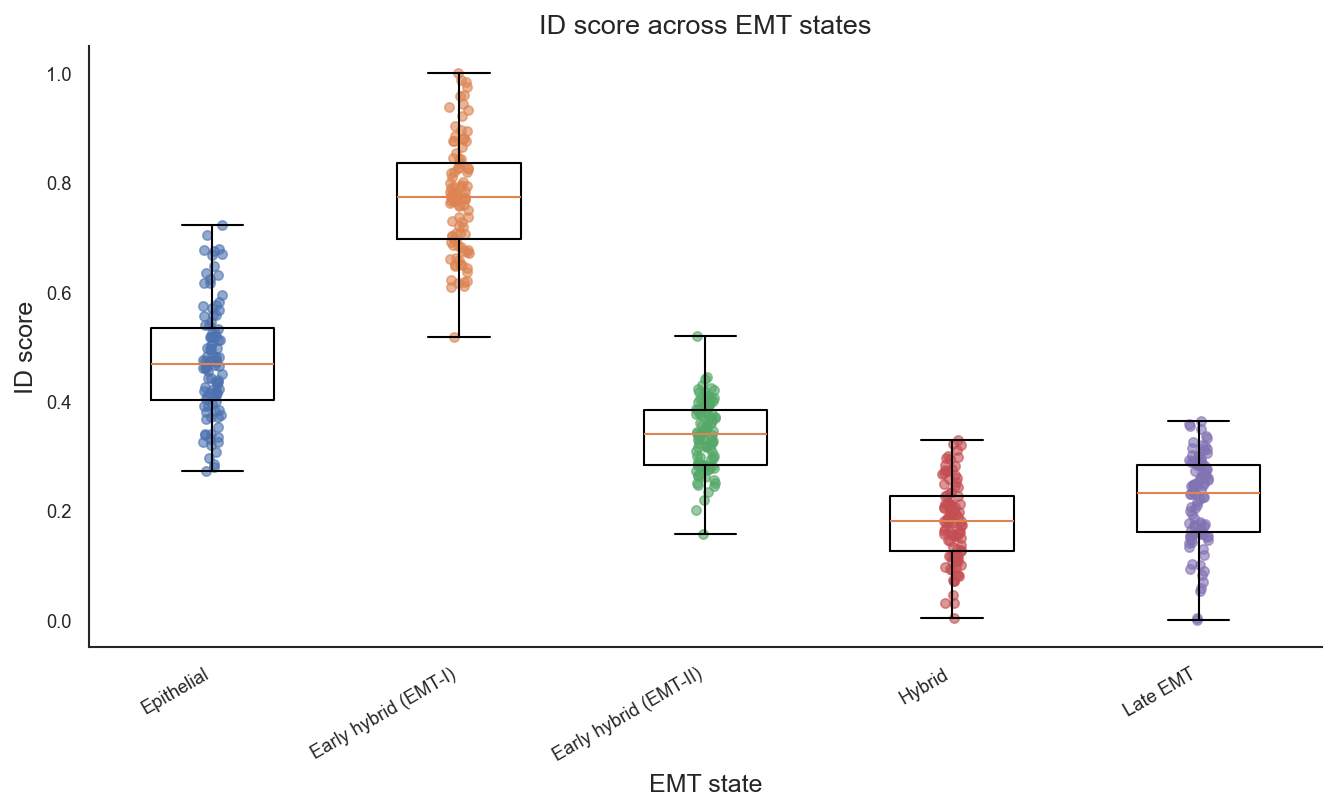

                       count    mean  median     std  median_raw_ID
Epithelial             100.0  0.4729  0.4673  0.1039        28.7019
Early hybrid (EMT-I)   100.0  0.7734  0.7737  0.1004        31.4932
Early hybrid (EMT-II)  100.0  0.3369  0.3391  0.0612        27.5340
Hybrid                 100.0  0.1810  0.1809  0.0720        26.0936
Late EMT               100.0  0.2193  0.2319  0.0804        26.5582


In [4]:
fig, ax = plt.subplots(figsize=(9, 5.5))

ax.boxplot([id_reps[s].dropna().values for s in ORDER],
           tick_labels=ORDER, showfliers=False)

rng = np.random.default_rng(42)
for i, state in enumerate(ORDER, start=1):
    v = id_reps[state].dropna().values
    ax.scatter(i + 0.04 * rng.uniform(-1, 1, len(v)), v, s=20, alpha=0.6)

ax.set_ylabel("Cluster-level ID score", fontsize=12)
ax.set_xlabel("EMT state", fontsize=12)
put_title(ax, "Cluster-level ID score across EMT states\n(2NN on 1,377-cell subsamples, 100 per state)", 12)
ax.set_xticks(range(1, len(ORDER) + 1))
ax.set_xticklabels(ORDER, rotation=30, ha="right")
sns.despine(ax=ax)
fig.tight_layout()
save(fig, "panel01_id_across_emt_states")
plt.show()

summary = pd.concat([id_reps[ORDER].agg(["count", "mean", "median", "std"]).T,
                     id_raw[ORDER].median().rename("median_raw_ID")], axis=1).round(4)
print(summary.to_string())
summary.to_csv(f"{SRC}/panel01_id_across_emt_states.csv")


---

## 4 · Statistics — Kruskal-Wallis and Dunn

The 100 replicates per state resample the same 14,302 cells, so these p-values speak to how
stable the estimate is, not to how many independent tumours were measured.


Kruskal-Wallis:  H = 416.21   p = 8.735e-89

               group1                group2         z            p  median_difference  rank_biserial            q signif
           Epithelial  Early hybrid (EMT-I) -5.418245 6.018693e-08          -0.306411        -0.9590 7.523367e-08   ****
           Epithelial Early hybrid (EMT-II)  4.485676 7.268297e-06           0.128213         0.7438 8.075886e-06   ****
           Epithelial                Hybrid 12.032360 2.401945e-33           0.286339         0.9910 8.006483e-33   ****
           Epithelial              Late EMT 10.245773 1.236321e-24           0.235332         0.9688 3.090803e-24   ****
 Early hybrid (EMT-I) Early hybrid (EMT-II)  9.903921 4.002659e-23           0.434624         0.9998 8.005317e-23   ****
 Early hybrid (EMT-I)                Hybrid 17.450605 3.406050e-68           0.592750         1.0000 3.406050e-67   ****
 Early hybrid (EMT-I)              Late EMT 15.664018 2.665130e-55           0.541743         1.0000 1.33256

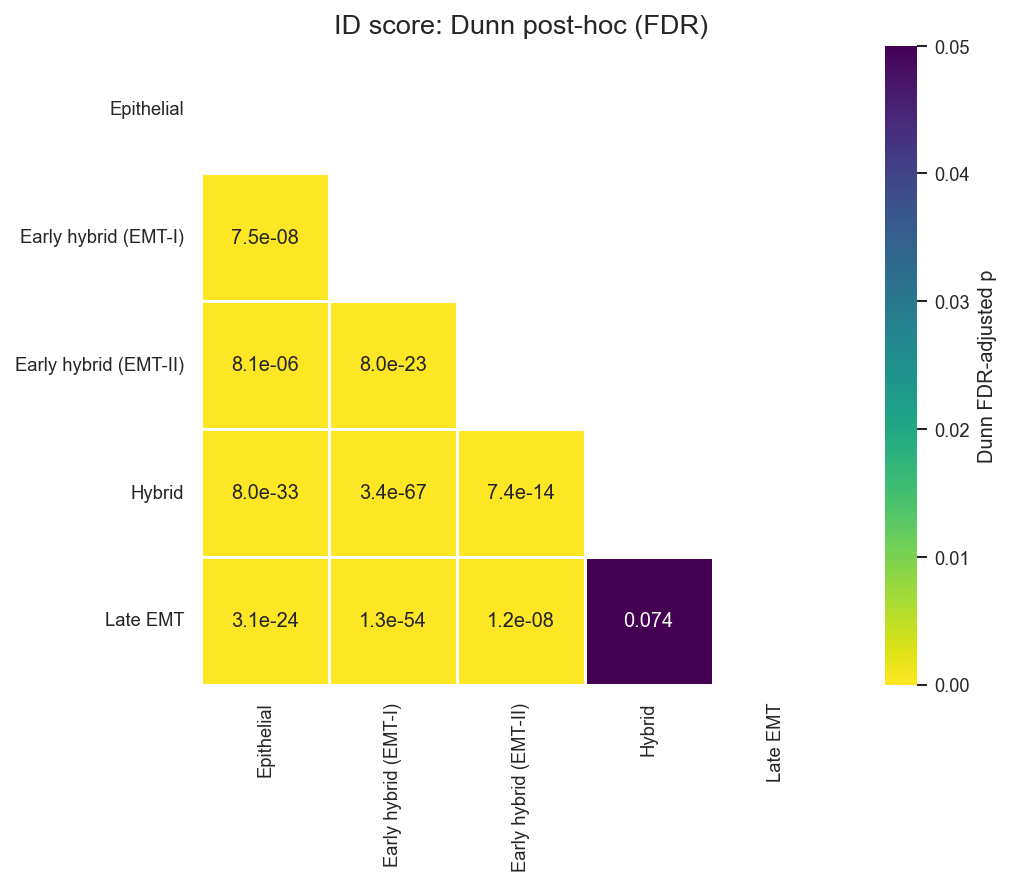

In [5]:
data = {s: id_reps[s].dropna().values for s in ORDER}
H, p_kw = kruskal(*[data[s] for s in ORDER])
print(f"Kruskal-Wallis:  H = {H:.2f}   p = {p_kw:.3e}\n")

tab = dunn(data, ORDER)
print(tab.to_string(index=False))
tab.to_csv(f"{SRC}/panel01_statistics.csv", index=False)

m = pd.DataFrame(np.nan, index=ORDER, columns=ORDER)
for _, r in tab.iterrows():
    m.loc[r["group2"], r["group1"]] = r["q"]
lab = m.map(lambda p: "" if pd.isna(p) else (f"{p:.1e}" if p < 1e-3 else f"{p:.3f}"))

fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(m.clip(upper=.05), mask=m.isna(), annot=lab, fmt="", cmap="viridis_r",
            vmin=0, vmax=.05, square=True, linewidths=.7, linecolor="white",
            cbar_kws={"label": "Dunn FDR-adjusted p"}, ax=ax)
put_title(ax, "Cluster-level ID score: Dunn post-hoc (FDR)")
fig.tight_layout()
save(fig, "panel02_id_dunn")
plt.show()


---

## 5 · Panel 3 — KS-Epi versus KS-Mes across EMT states

Each point is a cell, coloured by EMT state, with the overall linear trend dashed in black.
Code from `../src/analysis_notebooks/Multiome_cluster_id.ipynb` cell 15.


Pearson r = -0.074   p = 5.206e-19   n = 14,302

emt_state
Epithelial               5827
Early hybrid (EMT-I)     2472
Early hybrid (EMT-II)    1830
Hybrid                   1722
Late EMT                 2451
saved  figures/panel03_ks_epi_vs_mes.png  +  .pdf


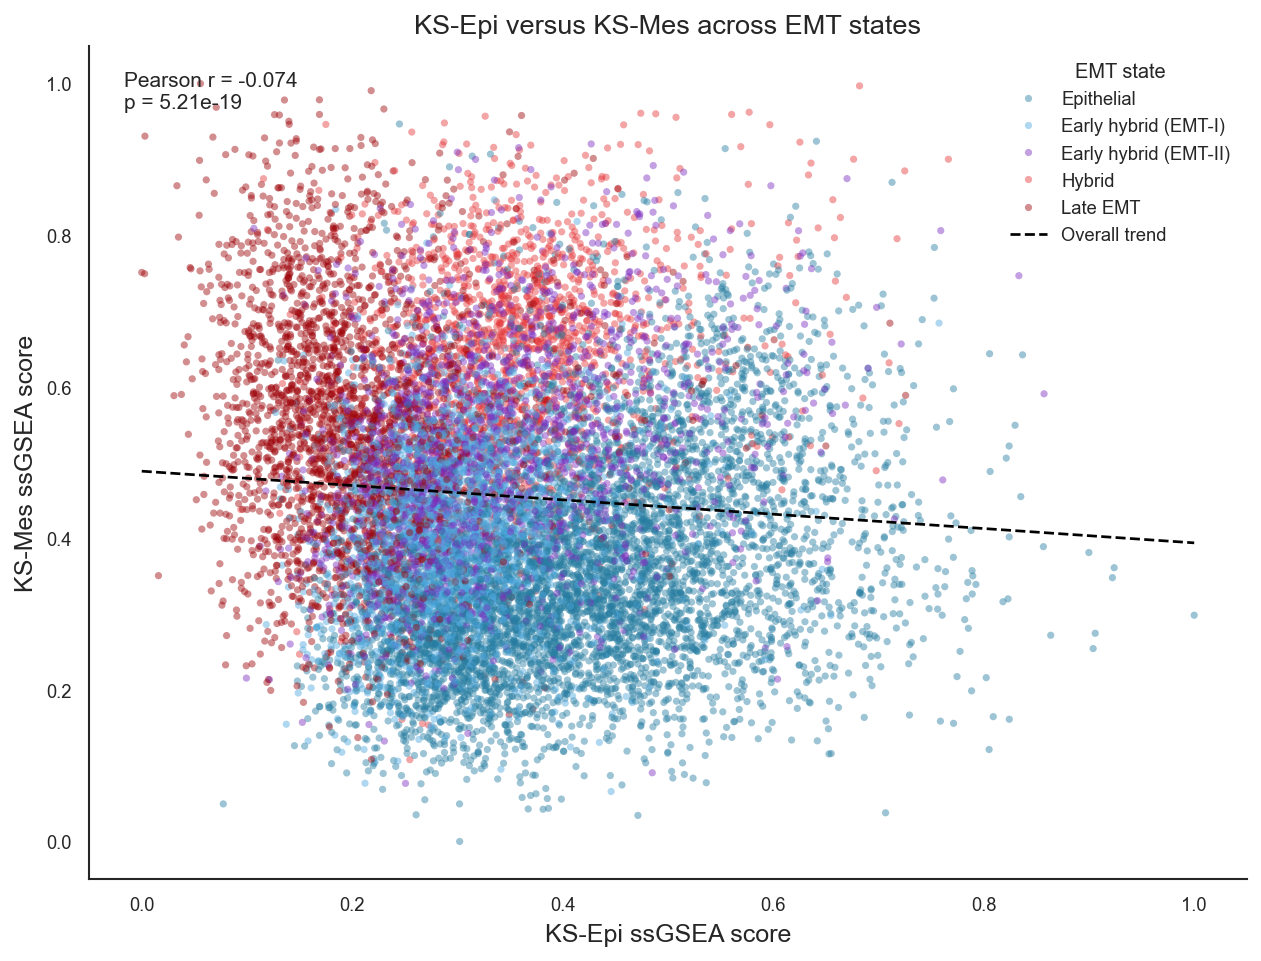

,emt_state,n,pearson_r,p
0,Epithelial,5827,0.351123,1.108615e-168
1,Early hybrid (EMT-I),2472,0.120302,1.971918e-09
2,Early hybrid (EMT-II),1830,0.295259,3.902226e-38
3,Hybrid,1722,0.228374,8.227397e-22
4,Late EMT,2451,-0.057640,4.309671e-03
5,all,14302,-0.074389,5.205970e-19


In [6]:
plot_df = (cells[["emt_state", "KS_Epi_ssGSEA", "KS_Mes_ssGSEA"]]
           .replace([np.inf, -np.inf], np.nan).dropna()
           .loc[lambda x: x["emt_state"].isin(ORDER)].copy())

r, p = pearsonr(plot_df["KS_Epi_ssGSEA"], plot_df["KS_Mes_ssGSEA"])
print(f"Pearson r = {r:.3f}   p = {p:.3e}   n = {len(plot_df):,}\n")
print(plot_df["emt_state"].value_counts().reindex(ORDER).to_string())

palette = {"Epithelial": "#277DA1", "Early hybrid (EMT-I)": "#4EA8DE",
           "Early hybrid (EMT-II)": "#7B2CBF", "Hybrid": "#E5383B",
           "Late EMT": "#9D0208"}

fig, ax = plt.subplots(figsize=(8.5, 6.5))
sns.scatterplot(data=plot_df, x="KS_Epi_ssGSEA", y="KS_Mes_ssGSEA",
                hue="emt_state", hue_order=ORDER, palette=palette,
                s=12, alpha=0.45, linewidth=0, rasterized=True, ax=ax)

x = plot_df["KS_Epi_ssGSEA"].to_numpy()
slope, intercept = np.polyfit(x, plot_df["KS_Mes_ssGSEA"].to_numpy(), 1)
x_line = np.linspace(0, 1, 200)
ax.plot(x_line, slope * x_line + intercept, color="black", linestyle="--",
        linewidth=1.3, label="Overall trend")

ax.set_xlabel("KS-Epi ssGSEA score", fontsize=12)
ax.set_ylabel("KS-Mes ssGSEA score", fontsize=12)
put_title(ax, "KS-Epi versus KS-Mes across EMT states")
p_text = "p < 1e-300" if p == 0 else f"p = {p:.2e}"
ax.text(0.03, 0.97, f"Pearson r = {r:.3f}\n{p_text}", transform=ax.transAxes,
        ha="left", va="top", fontsize=10)
ax.legend(title="EMT state", frameon=False, loc="best")
sns.despine(ax=ax)
fig.tight_layout()
save(fig, "panel03_ks_epi_vs_mes")
plt.show()

rows = []
for g in ORDER:
    s = plot_df[plot_df["emt_state"] == g]
    rg, pg = pearsonr(s["KS_Epi_ssGSEA"], s["KS_Mes_ssGSEA"])
    rows.append({"emt_state": g, "n": len(s), "pearson_r": rg, "p": pg})
rows.append({"emt_state": "all", "n": len(plot_df), "pearson_r": r, "p": p})
ks_stats = pd.DataFrame(rows)
ks_stats.to_csv(f"{SRC}/panel03_statistics.csv", index=False)
display(ks_stats)


---

## 6 · Source data

| File | Contents |
|---|---|
| `panel01_id_across_emt_states.csv` | ID: count, mean, median, sd per state, plus the raw median |
| `panel01_statistics.csv` | Kruskal-Wallis + Dunn table |
| `panel03_statistics.csv` | Pearson r per state and overall |
